# Dispersion Trading: Implied Correlation and the Price of Index Protection

An index is a portfolio, so its variance depends on its members' variances **and** on how they
move together:

$$\sigma_I^2 = \sum_i w_i^2\sigma_i^2 + \rho \sum_{i\neq j} w_i w_j \sigma_i \sigma_j .$$

Put the index implied vol and the members' implied vols in this formula and solve for $\rho$:
that is the **implied correlation** the option market is charging. Investors buy index puts
to protect their portfolios, so index vol is expensive and implied correlation is usually above the
correlation that is then realised. A **dispersion trade** sells index variance and buys
single-stock variance to collect that premium.

It is a short-correlation position: it earns a little most months and loses heavily when every
stock falls together. This notebook measures both sides on a simulated market with calm and
stressed regimes, and compares two ways of sizing the legs.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("dispersion.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/33-dispersion-trading")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dispersion import (Regimes, index_vol_from_corr, implied_correlation, simulate_market, realised_vol, run_dispersion,
                        strategy_stats)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
reg = Regimes()
w = np.full(10, 0.1)

## 1. Index volatility is mostly correlation

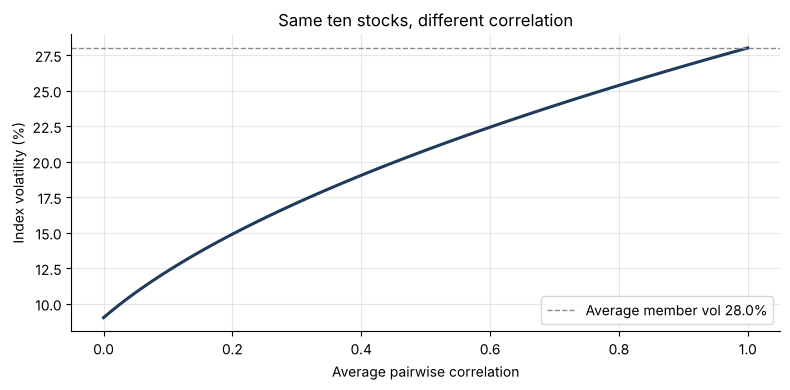

Index vol at rho = 0.3: 17.1%; at rho = 0.75: 24.7%


In [2]:
rhos = np.linspace(0, 1, 101)
base = np.array(reg.base_vols)
plt.figure(figsize=(8, 4))
plt.plot(rhos, [index_vol_from_corr(base, w, r) * 100 for r in rhos], color=NAVY, lw=2.2)
plt.axhline((w * base).sum() * 100, color=GREY, ls="--", lw=1, label=f"Average member vol {(w * base).sum():.1%}")
plt.xlabel("Average pairwise correlation"); plt.ylabel("Index volatility (%)"); plt.legend()
plt.title("Same ten stocks, different correlation")
plt.tight_layout(); plt.savefig("images/index_vol_vs_corr.png", dpi=150); plt.show()
print(f"Index vol at rho = 0.3: {index_vol_from_corr(base, w, 0.3):.1%}; at rho = 0.75: {index_vol_from_corr(base, w, 0.75):.1%}")

With the members' vols unchanged, moving from calm correlation (0.3) to stressed correlation
(0.75) raises index vol from about 17% to about 25%, more than 40% higher. Index options are
therefore, to a large extent, options on correlation.

## 2. A simulated market with calm and stressed regimes

Ten stocks, equally weighted. In calm periods the correlation is 0.30; in stress it jumps to 0.75
and every vol is multiplied by 1.9. Stress episodes are rare (about 15% of days) and arrive
without warning.

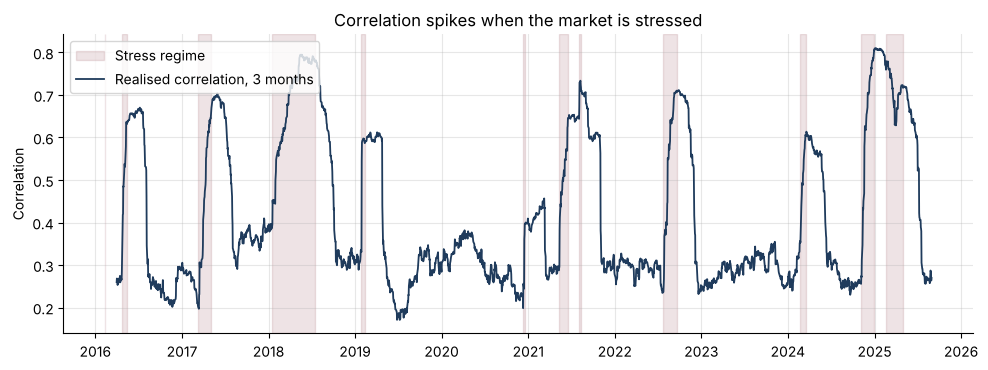

Share of stressed days: 16%; number of regime changes: 25


In [3]:
returns, stress = simulate_market(seed=0, reg=reg)
roll = 63
rc = [implied_correlation(realised_vol(returns.values[t - roll:t] @ w), realised_vol(returns.values[t - roll:t]), w)
      for t in range(roll, len(returns))]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(stress.index, 0, 1, where=stress.values == 1, color=BORDEAUX, alpha=0.12, transform=ax.get_xaxis_transform(), label="Stress regime")
ax.plot(returns.index[roll:], rc, color=NAVY, lw=1.3, label="Realised correlation, 3 months")
ax.set(ylabel="Correlation", title="Correlation spikes when the market is stressed"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("images/realised_corr.png", dpi=150); plt.show()
print(f"Share of stressed days: {stress.mean():.0%}; number of regime changes: {int((stress.diff() != 0).sum())}")

## 3. Strikes: fair value plus a risk premium

Every month the desk strikes one-month variance swaps on the index and on each stock. The
**fair** strike is the expected variance over the month given today's regime, including the
chance of switching regime (computed exactly from the Markov chain). The market adds a premium:
3% on single-stock vols and 12% on the index vol, the price of index protection.

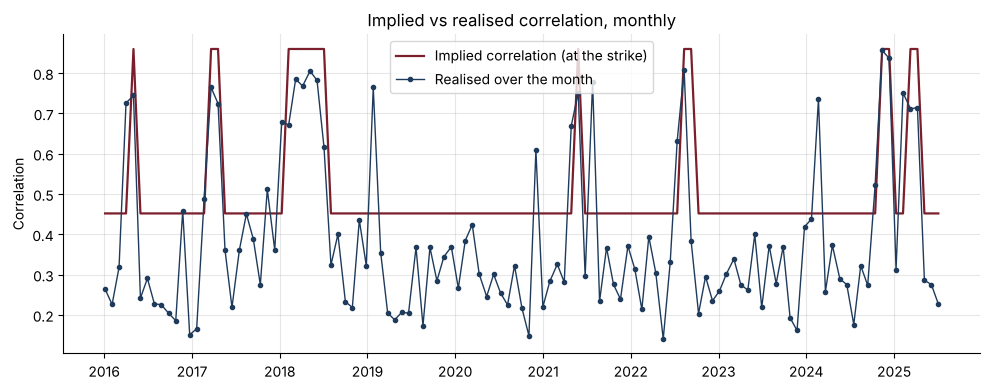

,implied corr,realised corr,implied index vol,realised index vol
Average,0.507,0.384,0.25,0.223


In [4]:
book = {s: run_dispersion(returns, stress, reg, scheme=s) for s in ("vega", "correlation")}
d = book["vega"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d.index, d["implied corr"], color=BORDEAUX, lw=1.6, label="Implied correlation (at the strike)")
ax.plot(d.index, d["realised corr"], color=NAVY, lw=1, marker=".", label="Realised over the month")
ax.set(ylabel="Correlation", title="Implied vs realised correlation, monthly"); ax.legend()
plt.tight_layout(); plt.savefig("images/implied_vs_realised.png", dpi=150); plt.show()
d[["implied corr", "realised corr", "implied index vol", "realised index vol"]].mean().round(3).to_frame("Average").T

On average the market charges an implied correlation about 12 points above what is realised. That
gap is what a dispersion trader is paid for. It is not free money: in a few months the realised
correlation jumps far above the strike.

## 4. Two ways to size the trade

The index leg is short EUR 10,000 of vega. The single-stock legs are long:
- **Vega-weighted**: the single-stock vegas add up to the index vega. Simple, but the trade is
  net long volatility, because the members' vols are higher than the index vol.
- **Correlation-weighted**: the single-stock legs are scaled down so that a general rise in every
  vol, with correlation unchanged, has no first-order effect (tested). What is left is a pure bet
  that correlation stays below its implied level.

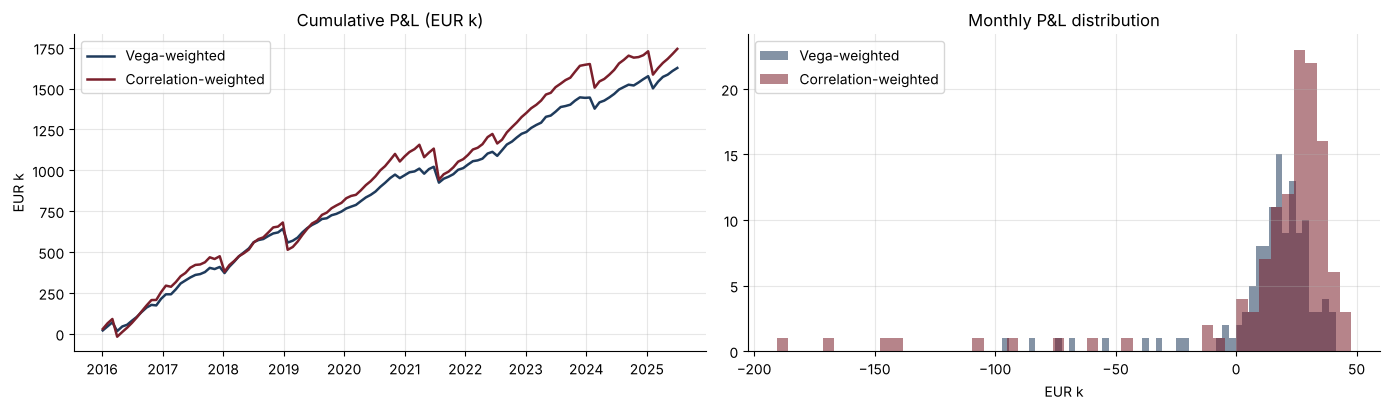

,Annual P&L (EUR),Annual vol (EUR),Sharpe,Positive months,Worst month (EUR),Skewness,Max drawdown (EUR)
Vega-weighted,164004.88,79793.53,2.06,0.89,-97132.36,-2.81,-97132.36
Correlation-weighted,175773.39,141410.90,1.24,0.90,-190600.88,-3.38,-214212.62


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
rows = {}
for (s, b), c in zip(book.items(), [NAVY, BORDEAUX]):
    label = "Vega-weighted" if s == "vega" else "Correlation-weighted"
    axes[0].plot(b.index, b["P&L"].cumsum() / 1e3, color=c, lw=1.8, label=label)
    axes[1].hist(b["P&L"] / 1e3, bins=50, color=c, alpha=0.55, label=label)
    rows[label] = strategy_stats(b["P&L"])
axes[0].set(title="Cumulative P&L (EUR k)", ylabel="EUR k"); axes[0].legend()
axes[1].set(title="Monthly P&L distribution", xlabel="EUR k"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/dispersion_pnl.png", dpi=150); plt.show()
pd.DataFrame(rows).T.round(2)

Both versions win about nine months out of ten, and both have the fat left tail of a
short-insurance strategy: strongly negative skew, losses concentrated in a few months. The
correlation-weighted version earns slightly more in total, but the vega-weighted one has the
better Sharpe ratio: its hidden long-vol position pays exactly when correlation spikes, since vols
rise at the same time. The correlation-weighted version shows the real tail of the correlation
bet: a worst month about twice as large.

## 5. When does it lose?

In [6]:
b = book["correlation"]
worst = b.nsmallest(6, "P&L")[["stress at start", "stress share", "implied corr", "realised corr", "P&L single legs", "P&L index leg", "P&L"]]
worst.round(2)

,stress at start,stress share,implied corr,realised corr,P&L single legs,P&L index leg,P&L
date,,,,,,,
2021-07-26,0,0.38,0.45,0.78,232428.56,-423029.43,-190600.88
2019-01-25,0,0.62,0.45,0.76,205468.52,-372347.22,-166878.70
2024-02-21,0,0.81,0.45,0.73,190620.45,-335299.39,-144678.94
2025-02-07,0,0.67,0.45,0.75,169080.20,-311822.73,-142742.52
2016-04-01,0,0.33,0.45,0.73,136267.69,-244792.32,-108524.63
2018-01-09,0,0.76,0.45,0.68,143483.63,-238465.59,-94981.96


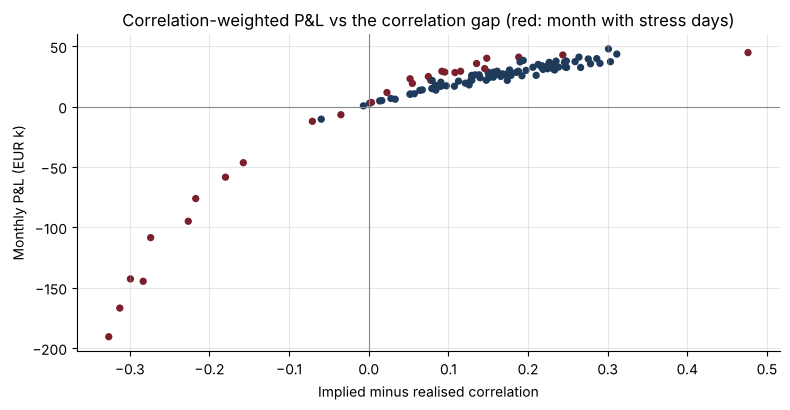

In [7]:
plt.figure(figsize=(8, 4.2))
plt.scatter(b["implied corr"] - b["realised corr"], b["P&L"] / 1e3, c=np.where(b["stress share"] > 0, BORDEAUX, NAVY), s=18)
plt.axhline(0, color=GREY, lw=0.8); plt.axvline(0, color=GREY, lw=0.8)
plt.xlabel("Implied minus realised correlation"); plt.ylabel("Monthly P&L (EUR k)")
plt.title("Correlation-weighted P&L vs the correlation gap (red: month with stress days)")
plt.tight_layout(); plt.savefig("images/pnl_vs_corr_gap.png", dpi=150); plt.show()

Every large loss is a month that **started calm and turned stressed**: the strikes were set for a
calm market, then correlation jumped. The single-stock legs gain a lot in those months, but the
short index leg loses almost twice as much. Months that start in stress all made money on this
history, because the strikes already priced the stressed level. The P&L lines up with the
correlation gap, as a pure correlation trade should.

## 6. Where does the money come from?

Remove the extra premium on index vol and the trade has nothing left to collect.

In [8]:
grid = []
for prem in (0.03, 0.06, 0.09, 0.12, 0.15):
    row = {"Index vol premium": prem}
    for s in ("vega", "correlation"):
        st = strategy_stats(run_dispersion(returns, stress, reg, index_premium=prem, scheme=s)["P&L"])
        row[f"Sharpe ({s})"] = st["Sharpe"]
        row[f"Annual P&L ({s}, EUR k)"] = st["Annual P&L (EUR)"] / 1e3
    grid.append(row)
pd.DataFrame(grid).set_index("Index vol premium").round(2)

,Sharpe (vega),"Annual P&L (vega, EUR k)",Sharpe (correlation),"Annual P&L (correlation, EUR k)"
Index vol premium,,,,
0.03,-0.71,-73.37,-0.34,-62.70
0.06,0.09,7.96,0.11,19.00
0.09,1.01,87.02,0.64,98.43
0.12,2.06,164.00,1.24,175.77
0.15,3.16,239.07,1.92,251.20


With the same 3% premium on the index as on the stocks (first line), there is no correlation
premium left and both versions lose money on this history. They roughly break even at 6%, and a
Sharpe ratio above 1 needs about 9 to 12%. The edge of a dispersion trade *is* the index
protection premium, and how much of it the market pays decides everything.

## 7. Robustness over 6 simulated markets

In [9]:
rob = []
for seed in range(6):
    r_, s_ = simulate_market(seed=seed, reg=reg)
    row = {"seed": seed, "Stress days": s_.mean()}
    for s in ("vega", "correlation"):
        st = strategy_stats(run_dispersion(r_, s_, reg, scheme=s)["P&L"])
        row[f"Sharpe ({s})"], row[f"Worst month ({s}, EUR k)"], row[f"Skew ({s})"] = st["Sharpe"], st["Worst month (EUR)"] / 1e3, st["Skewness"]
    rob.append(row)
rob = pd.DataFrame(rob).set_index("seed")
pd.concat([rob, rob.mean().to_frame("Average").T]).round(2)

,Stress days,Sharpe (vega),"Worst month (vega, EUR k)",Skew (vega),Sharpe (correlation),"Worst month (correlation, EUR k)",Skew (correlation)
0,0.16,2.06,-97.13,-2.81,1.24,-190.60,-3.38
1,0.13,2.70,-82.72,-2.66,1.94,-166.34,-3.80
2,0.18,2.53,-92.88,-3.16,1.62,-176.06,-3.95
3,0.15,1.78,-119.83,-2.85,1.11,-234.55,-3.51
4,0.12,2.22,-169.89,-5.02,1.54,-302.29,-5.88
5,0.14,3.13,-83.40,-2.22,2.21,-172.72,-3.61
Average,0.15,2.40,-107.64,-3.12,1.61,-207.09,-4.02


In all six markets the vega-weighted version has the higher Sharpe ratio and the
correlation-weighted version the worse tail. The Sharpe ratios themselves depend on the 12%
premium assumed here: on real data the premium varies over time and crashes can be faster than a
regime switch, so the tail would be worse.

## Conclusions
- Implied correlation is read directly from index and single-stock vols (tested against the
  inverse formula). It sits above realised correlation because index protection is in demand.
- A dispersion trade collects that premium. It wins most months, has strongly negative skew, and
  its losses come from calm markets that turn stressed.
- The sizing of the legs decides what the trade really is: vega-weighted is partly a long-vol
  trade that cushions crises; correlation-weighted isolates the correlation bet and its full tail.
- **Next steps:** real index and single-stock implied vols (implied correlation indices exist for
  major indices), options instead of variance swaps (gamma and vega management), stop-losses or
  index put overlays to cut the tail, and trading only when the correlation premium is wide.